In [1]:
!kaggle datasets download pratyushakar/rossmann-store-sales

Dataset URL: https://www.kaggle.com/datasets/pratyushakar/rossmann-store-sales
License(s): CC0-1.0
100% 6.90M/6.90M [00:00<00:00, 81.4MB/s]



In [2]:
!unzip rossmann-store-sales.zip

Archive:  rossmann-store-sales.zip
  inflating: store.csv               
  inflating: test.csv                
  inflating: train.csv               


In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import plotly.express as px
from matplotlib import pyplot as plt
import xgboost as xgb
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)
#pd.set_option('display.max_rows', None)
pd.set_option('display.float_format', lambda x: '%.3f' % x)
pd.set_option('display.width', 500)
from sklearn.preprocessing import MinMaxScaler, LabelEncoder, StandardScaler, RobustScaler, OneHotEncoder
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.compose import ColumnTransformer

### Rossmann Store Sales - Sütun İzahları

| Sütun Adı | Təsviri / İzahı |
| :--- | :--- |
| **Store** | Hər bir mağaza üçün unikal identifikasiya nömrəsi (ID). |
| **DayOfWeek** | Həftənin günü (1 = Bazardüzü, 7 = Bazar). |
| **Date** | Məlumatın qeydə alındığı tarix. |
| **Open** | Mağazanın açıq olub-olmaması göstəricisi (0 = Bağlı, 1 = Açıq). |
| **Promo** | Həmin gün mağazada kampaniya/aksiya olub-olmaması (0 = Yoxdur, 1 = Var). |
| **StateHoliday** | Dövlət bayramı göstəricisi (a = İctimai bayram, b = Pasxa, c = Milad, 0 = Bayram deyil). |
| **SchoolHoliday** | Həmin gün məktəb tətilinə düşüb-düşməməsi (0 = Xeyr, 1 = Bəli). |
| **StoreType** | Mağazanın modeli/tipi (4 fərqli mağaza modeli: a, b, c, d). |
| **Assortment** | Mağazanın çeşid/məhsul səviyyəsi (a = Əsas/Basic, b = Genişləndirilmiş/Extra, c = Geniş/Extended). |
| **CompetitionDistance** | Ən yaxın rəqib mağazaya qədər olan məsafə (metr ilə). |
| **CompetitionOpenSinceMonth** | Ən yaxın rəqib mağazanın açıldığı ay (1–12). |
| **CompetitionOpenSinceYear** | Ən yaxın rəqib mağazanın açıldığı il. |
| **Promo2** | Mağazanın davamlı/dövri kampaniyada iştirak edib-etməməsi (0 = Etmir, 1 = Edir). |
| **Promo2SinceWeek** | Mağazanın Promo2 kampaniyasına başladığı təqvim həftəsi (1–52). |
| **Promo2SinceYear** | Mağazanın Promo2 kampaniyasına başladığı il. |
| **PromoInterval** | Promo2-nin təkrarlandığı aylar (məsələn: "Feb,May,Aug,Nov"). |

# **EDA**

In [4]:
df_sales_raw = pd.read_csv('/content/test.csv', low_memory = False)
df_store_raw = pd.read_csv('/content/store.csv', low_memory = False)
df_raw = pd.merge(df_sales_raw, df_store_raw, how = 'left', on = 'Store')
df_raw.head(5)

,Id,Store,DayOfWeek,Date,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,1,4,2015-09-17,1.000,1,0,0,c,a,1270.000,9.000,2008.000,0,NaN,NaN,NaN
1,2,3,4,2015-09-17,1.000,1,0,0,a,a,14130.000,12.000,2006.000,1,14.000,2011.000,"Jan,Apr,Jul,Oct"
2,3,7,4,2015-09-17,1.000,1,0,0,a,c,24000.000,4.000,2013.000,0,NaN,NaN,NaN
3,4,8,4,2015-09-17,1.000,1,0,0,a,a,7520.000,10.000,2014.000,0,NaN,NaN,NaN
4,5,9,4,2015-09-17,1.000,1,0,0,a,c,2030.000,8.000,2000.000,0,NaN,NaN,NaN


In [5]:
df_raw.shape

(41088, 17)

In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Id                         41088 non-null  int64  
 1   Store                      41088 non-null  int64  
 2   DayOfWeek                  41088 non-null  int64  
 3   Date                       41088 non-null  object 
 4   Open                       41077 non-null  float64
 5   Promo                      41088 non-null  int64  
 6   StateHoliday               41088 non-null  object 
 7   SchoolHoliday              41088 non-null  int64  
 8   StoreType                  41088 non-null  object 
 9   Assortment                 41088 non-null  object 
 10  CompetitionDistance        40992 non-null  float64
 11  CompetitionOpenSinceMonth  25872 non-null  float64
 12  CompetitionOpenSinceYear   25872 non-null  float64
 13  Promo2                     41088 non-null  int

In [7]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,41088.000,20544.500,11861.228,1.000,10272.750,20544.500,30816.250,41088.000
Store,41088.000,555.900,320.274,1.000,279.750,553.500,832.250,1115.000
DayOfWeek,41088.000,3.979,2.015,1.000,2.000,4.000,6.000,7.000
Open,41077.000,0.854,0.353,0.000,1.000,1.000,1.000,1.000
Promo,41088.000,0.396,0.489,0.000,0.000,0.000,1.000,1.000
SchoolHoliday,41088.000,0.443,0.497,0.000,0.000,0.000,1.000,1.000
CompetitionDistance,40992.000,5088.583,7225.487,20.000,720.000,2425.000,6480.000,75860.000
CompetitionOpenSinceMonth,25872.000,7.035,3.143,1.000,4.000,7.000,9.000,12.000
CompetitionOpenSinceYear,25872.000,2008.642,6.862,1900.000,2006.000,2010.000,2012.000,2015.000
Promo2,41088.000,0.581,0.493,0.000,0.000,1.000,1.000,1.000


In [8]:
df_raw.isnull().sum()

,0
Id,0
Store,0
DayOfWeek,0
Date,0
Open,11
Promo,0
StateHoliday,0
SchoolHoliday,0
StoreType,0
Assortment,0


In [9]:
df_raw.duplicated().sum()

np.int64(0)

In [10]:
df_raw.nunique()

,0
Id,41088
Store,856
DayOfWeek,7
Date,48
Open,2
Promo,2
StateHoliday,2
SchoolHoliday,2
StoreType,4
Assortment,3


In [11]:
df_raw['Date'] = pd.to_datetime(df_raw['Date'])

In [12]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41088 entries, 0 to 41087
Data columns (total 17 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Id                         41088 non-null  int64         
 1   Store                      41088 non-null  int64         
 2   DayOfWeek                  41088 non-null  int64         
 3   Date                       41088 non-null  datetime64[ns]
 4   Open                       41077 non-null  float64       
 5   Promo                      41088 non-null  int64         
 6   StateHoliday               41088 non-null  object        
 7   SchoolHoliday              41088 non-null  int64         
 8   StoreType                  41088 non-null  object        
 9   Assortment                 41088 non-null  object        
 10  CompetitionDistance        40992 non-null  float64       
 11  CompetitionOpenSinceMonth  25872 non-null  float64       
 12  Comp

In [13]:
df_raw = df_raw.sort_values(by=['Date', 'Store']).reset_index(drop=True)

* **`CompetitionDistance` (Rəqibə olan məsafə):**
Boşdursa, deməli yaxınlıqda heç bir rəqib yoxdur. Bura maksimum məsafədən də böyük bir ədəd (**200,000**) yazırıq.
* **`CompetitionOpenSince[Month/Year]` (Rəqibin açılış tarixi):**
Boş (`NaN`) dəyərləri cari satımın baş verdiyi `date` (tarix) sütunundakı ay və il ilə doldururuq.
* **`Promo2Since[Year/Week]` (Promo2-nin başlama tarixi):**
Aksiya başlama tarixi boşdursa, yenə də `date` sütunundakı ay və ili yazırıq.
* **`PromoInterval` (Aksiya ayları):**
Boş dəyərləri **0** edirik. Sonra mağazanın həmin ay aksiyada olub-olmadığını `is_promo` sütununda **1** (bəli) və **0** (xeyr) kimi qeyd edirik.

In [14]:
df_raw['CompetitionDistance'].fillna(200000, inplace = True)

df_raw['CompetitionOpenSinceMonth'].fillna(df_raw['Date'].dt.month, inplace = True)

df_raw['CompetitionOpenSinceYear'].fillna(df_raw['Date'].dt.year, inplace = True)

df_raw['Promo2SinceWeek'].fillna(df_raw['Date'].dt.isocalendar().week, inplace = True)

df_raw['Promo2SinceYear'].fillna(df_raw['Date'].dt.year, inplace = True)

month_map = {1 : 'Jan', 2 : 'Fev', 3 : 'Mar', 4 : 'Apr', 5 : 'May', 6 : 'Jun', 7 : 'Jul', 8 : 'Aug', 9 : 'Sep',
 10 : 'Oct', 11 : 'Nov', 12 : 'Dec'}

df_raw['PromoInterval'].fillna(0, inplace = True)

df_raw['month_map'] = df_raw['Date'].dt.month.map( month_map )

df_raw['is_promo'] = df_raw[['PromoInterval', 'month_map']].apply( lambda x: 0 if x['PromoInterval'] == 0 else 1 if x['month_map'] in x['PromoInterval'].split( ',' ) else 0, axis=1 )

In [15]:
df_raw.isna().sum().sort_values(ascending = False)

,0
Open,11
Store,0
Id,0
DayOfWeek,0
Date,0
Promo,0
StateHoliday,0
SchoolHoliday,0
StoreType,0
Assortment,0


In [16]:
df_train_sales_raw = pd.read_csv('/content/train.csv', low_memory = False)
df_train = pd.merge(df_train_sales_raw, df_store_raw, how = 'left', on = 'Store')
df_train.head()

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.000,9.000,2008.000,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.000,11.000,2007.000,1,13.000,2010.000,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.000,12.000,2006.000,1,14.000,2011.000,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.000,9.000,2009.000,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.000,4.000,2015.000,0,NaN,NaN,NaN


In [17]:
# Apply the Sales > 0 filter
df_train = df_train[df_train['Sales'] > 0]
display(df_train.head())

,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.000,9.000,2008.000,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.000,11.000,2007.000,1,13.000,2010.000,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.000,12.000,2006.000,1,14.000,2011.000,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.000,9.000,2009.000,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.000,4.000,2015.000,0,NaN,NaN,NaN


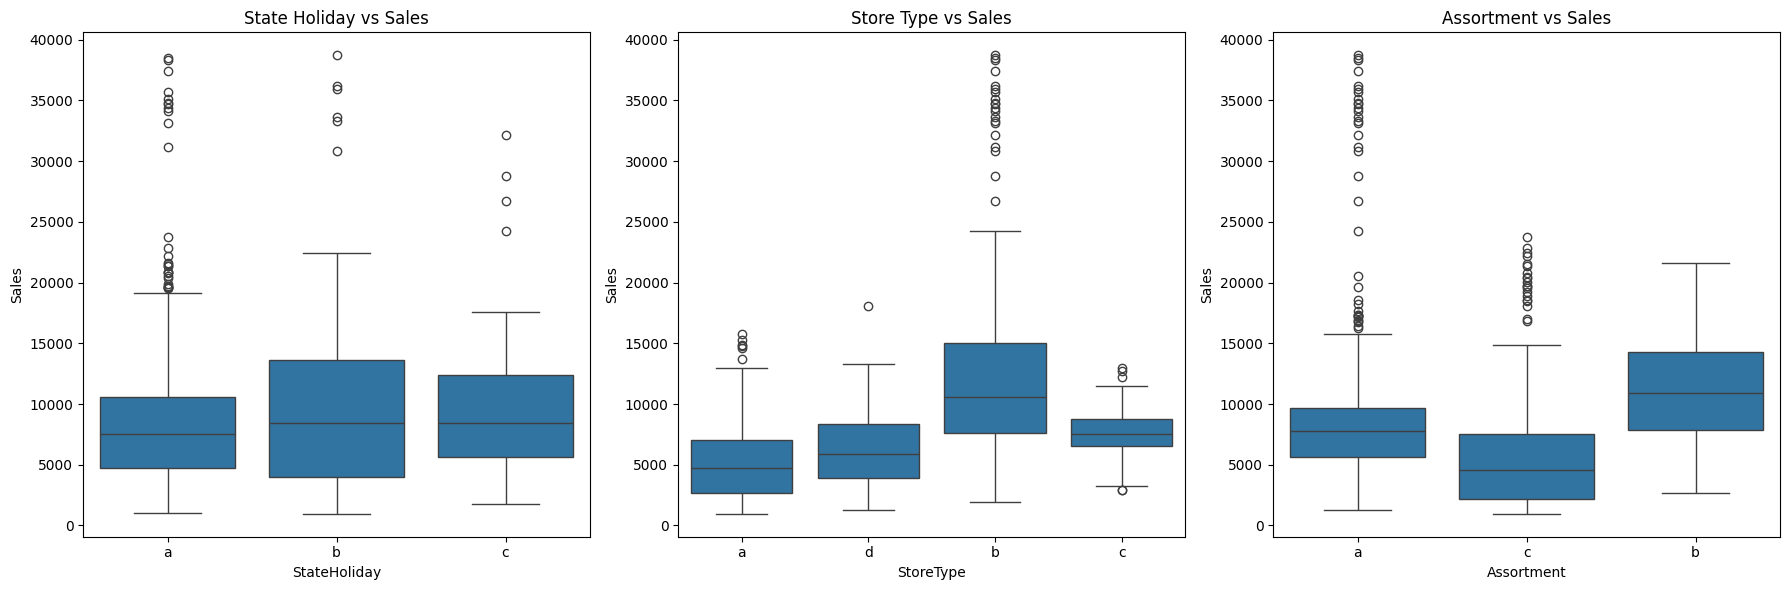

In [18]:
aux1 = df_train[(df_train['StateHoliday'] != '0') & (df_train['Sales'] > 0)]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

sns.boxplot(x='StateHoliday', y='Sales', data=aux1, ax=axes[0])
axes[0].set_title('State Holiday vs Sales')

sns.boxplot(x='StoreType', y='Sales', data=aux1, ax=axes[1])
axes[1].set_title('Store Type vs Sales')

sns.boxplot(x='Assortment', y='Sales', data=aux1, ax=axes[2])
axes[2].set_title('Assortment vs Sales')

plt.tight_layout()
plt.show()

In [19]:
df1 = df_raw.copy()

In [20]:
import datetime

df1['Year'] = df1['Date'].dt.year
df1['Month'] = df1['Date'].dt.month
df1['Day'] = df1['Date'].dt.day
df1['WeekOfYear'] = df1['Date'].dt.isocalendar().week

df1['YearWeek'] = df1['Date'].dt.strftime('%Y-%U')

df1['CompetitionOpen'] = 12 * (df1['Year'] - df1['CompetitionOpenSinceYear']) + (df1['Month'] - df1['CompetitionOpenSinceMonth'])

df1['PromoSince'] = df1['Promo2SinceYear'].astype(int).astype(str) + '-' + df1['Promo2SinceWeek'].astype(int).astype(str)
df1['PromoSince'] = df1['PromoSince'].apply(lambda x: datetime.datetime.strptime(x + '-1', '%Y-%W-%w') - datetime.timedelta(days = 7))
df1['PromoTimeWeek'] = ((df1['Date'] - df1['PromoSince'])/7).apply(lambda x: x.days).astype(int)

#a = basic, b = extra, c = extended
assortment = {'a' : 'basic', 'b' : 'extra', 'c' : 'extended'}
df1['Assortment'] = df1['Assortment'].map(assortment)

#a = PublicHoliday, b = EasterHoliday, c = Christmas, 0 = RegularDay
state_holiday = {'a' : 'PublicHoliday', 'b' : 'EasterHoliday', 'c' : 'Christmas', '0' : 'RegularDay'}
df1['StateHoliday'] = df1['StateHoliday'].map(state_holiday)

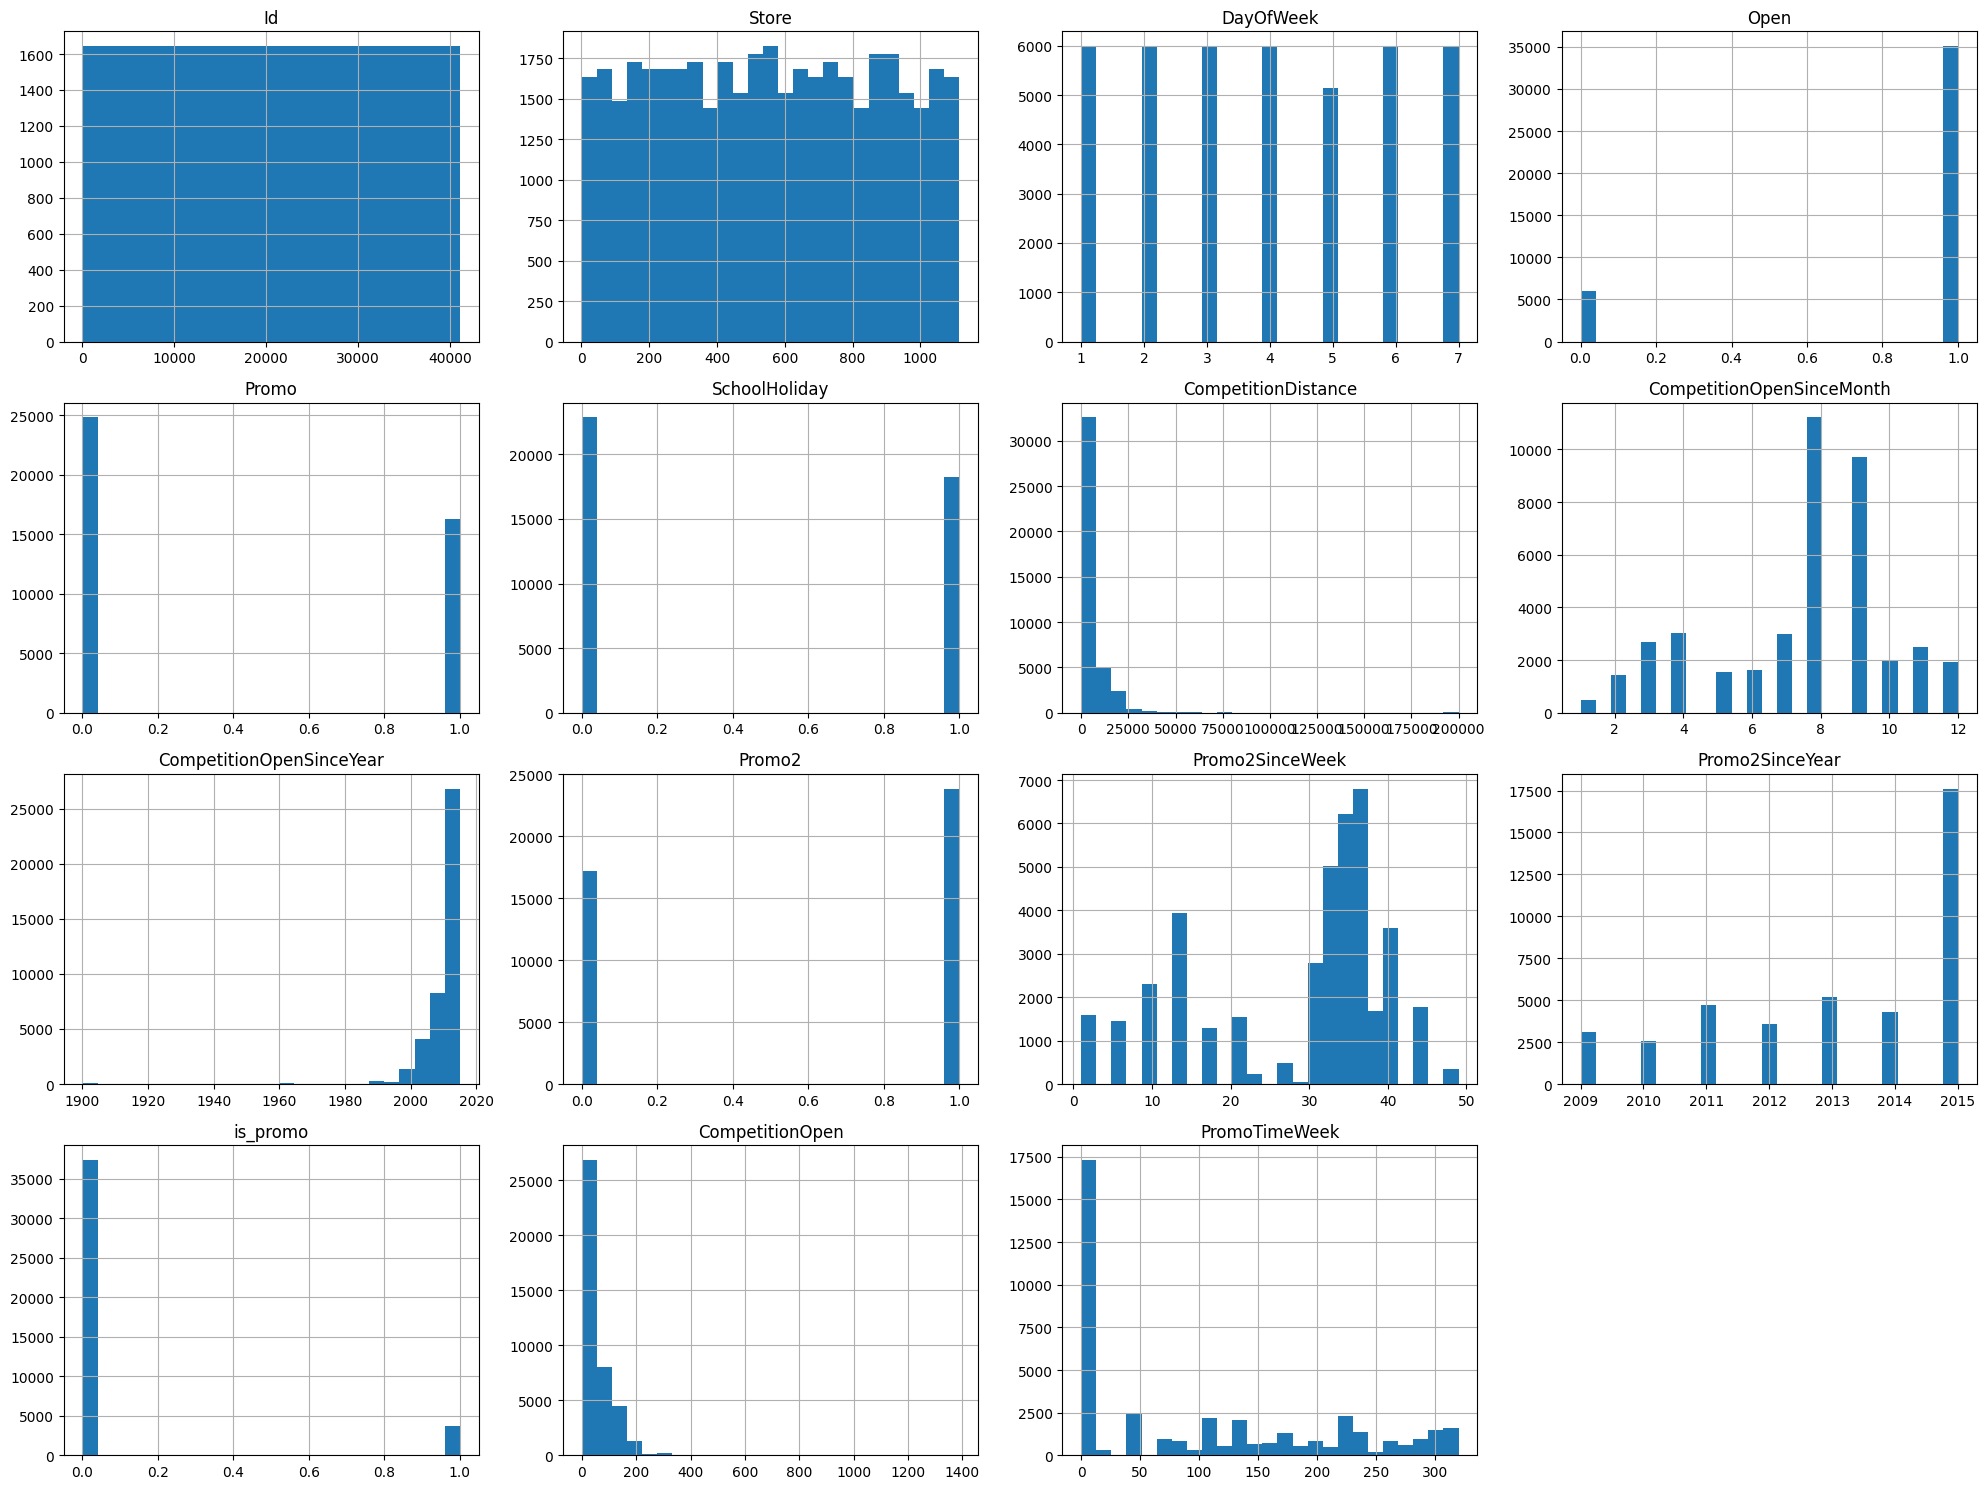

In [21]:
num_attributes = df1.select_dtypes(include=['int64', 'float64'])
num_attributes.hist(bins=25, figsize=(20, 15))
plt.tight_layout()
plt.show()

In [22]:
df1.select_dtypes(include = 'object').columns

Index(['StateHoliday', 'StoreType', 'Assortment', 'PromoInterval', 'month_map', 'YearWeek'], dtype='object')

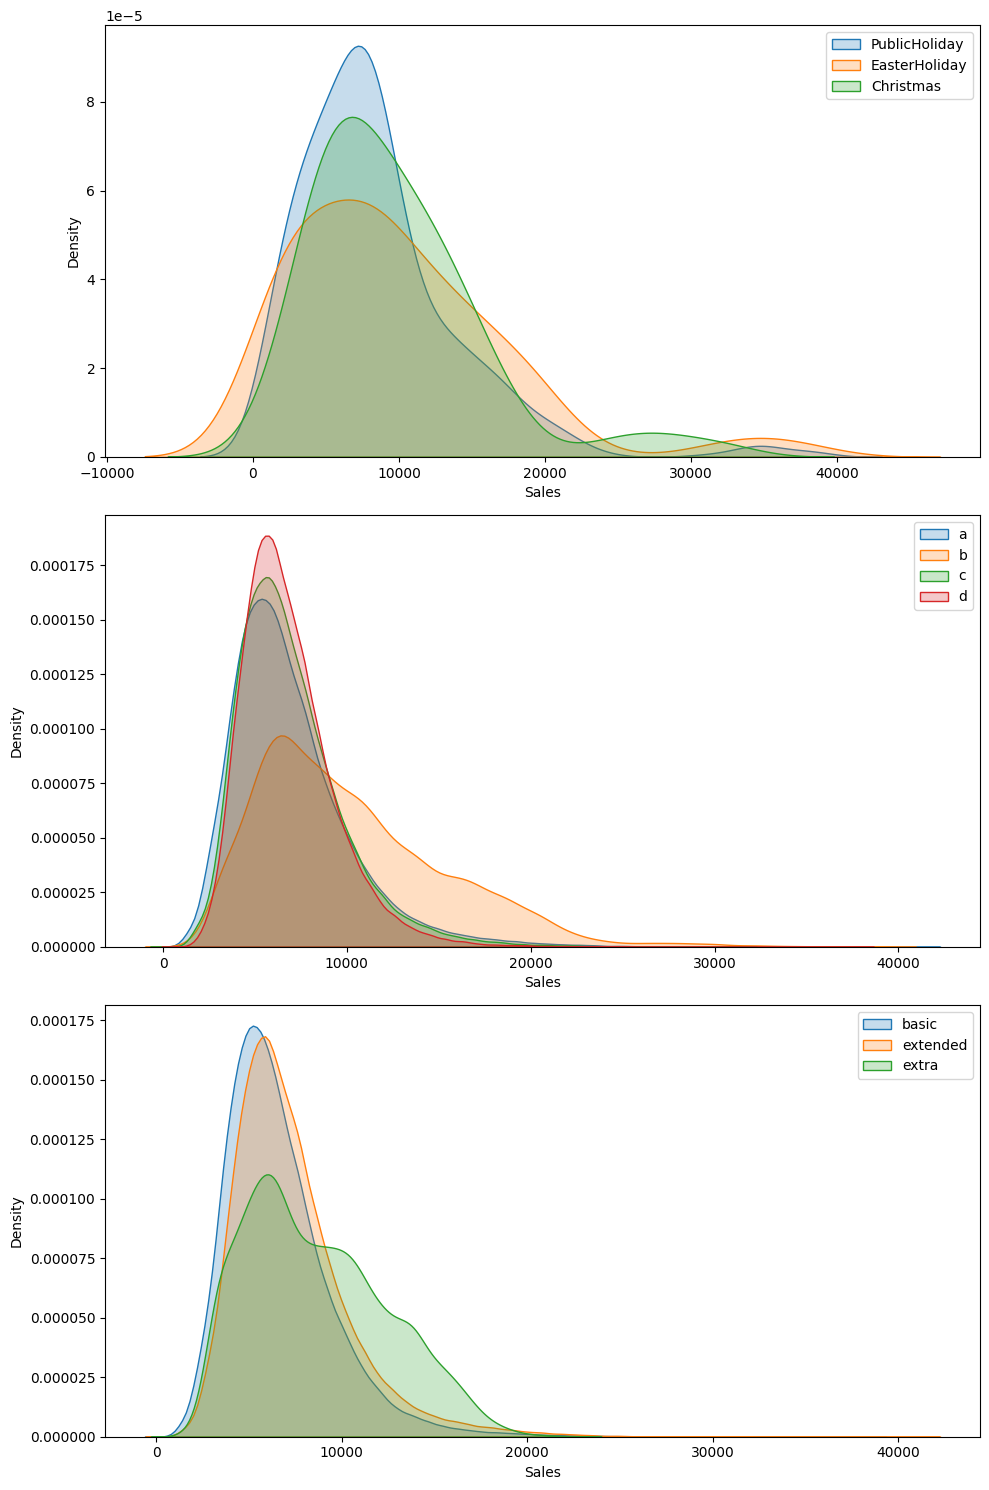

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(10, 15))

df_train_processed = df_train.copy()

state_holiday_map = {'a' : 'PublicHoliday', 'b' : 'EasterHoliday', 'c' : 'Christmas', '0' : 'RegularDay'}
df_train_processed['StateHoliday'] = df_train_processed['StateHoliday'].map(state_holiday_map)

assortment_map = {'a' : 'basic', 'b' : 'extra', 'c' : 'extended'}
df_train_processed['Assortment'] = df_train_processed['Assortment'].map(assortment_map)

# 1. KDE plot: StateHoliday vs Sales
aux_train_holiday_sales = df_train_processed[(df_train_processed['StateHoliday'] != 'RegularDay') & (df_train_processed['Sales'] > 0)]
sns.kdeplot(x=aux_train_holiday_sales[aux_train_holiday_sales['StateHoliday'] == 'PublicHoliday']['Sales'], label='PublicHoliday', fill=True, ax=axes[0])
sns.kdeplot(x=aux_train_holiday_sales[aux_train_holiday_sales['StateHoliday'] == 'EasterHoliday']['Sales'], label='EasterHoliday', fill=True, ax=axes[0])
sns.kdeplot(x=aux_train_holiday_sales[aux_train_holiday_sales['StateHoliday'] == 'Christmas']['Sales'], label='Christmas', fill=True, ax=axes[0])
axes[0].legend()

# 2. KDE plot: StoreType vs Sales
aux_train_storetype_sales = df_train_processed[df_train_processed['Sales'] > 0]
sns.kdeplot(x=aux_train_storetype_sales[aux_train_storetype_sales['StoreType'] == 'a']['Sales'], label='a', fill=True, ax=axes[1])
sns.kdeplot(x=aux_train_storetype_sales[aux_train_storetype_sales['StoreType'] == 'b']['Sales'], label='b', fill=True, ax=axes[1])
sns.kdeplot(x=aux_train_storetype_sales[aux_train_storetype_sales['StoreType'] == 'c']['Sales'], label='c', fill=True, ax=axes[1])
sns.kdeplot(x=aux_train_storetype_sales[aux_train_storetype_sales['StoreType'] == 'd']['Sales'], label='d', fill=True, ax=axes[1])
axes[1].legend()

# 3. KDE plot: Assortment vs Sales
aux_train_assortment_sales = df_train_processed[df_train_processed['Sales'] > 0]
sns.kdeplot(x=aux_train_assortment_sales[aux_train_assortment_sales['Assortment'] == 'basic']['Sales'], label='basic', fill=True, ax=axes[2])
sns.kdeplot(x=aux_train_assortment_sales[aux_train_assortment_sales['Assortment'] == 'extended']['Sales'], label='extended', fill=True, ax=axes[2])
sns.kdeplot(x=aux_train_assortment_sales[aux_train_assortment_sales['Assortment'] == 'extra']['Sales'], label='extra', fill=True, ax=axes[2])
axes[2].legend()

plt.tight_layout()
plt.show()

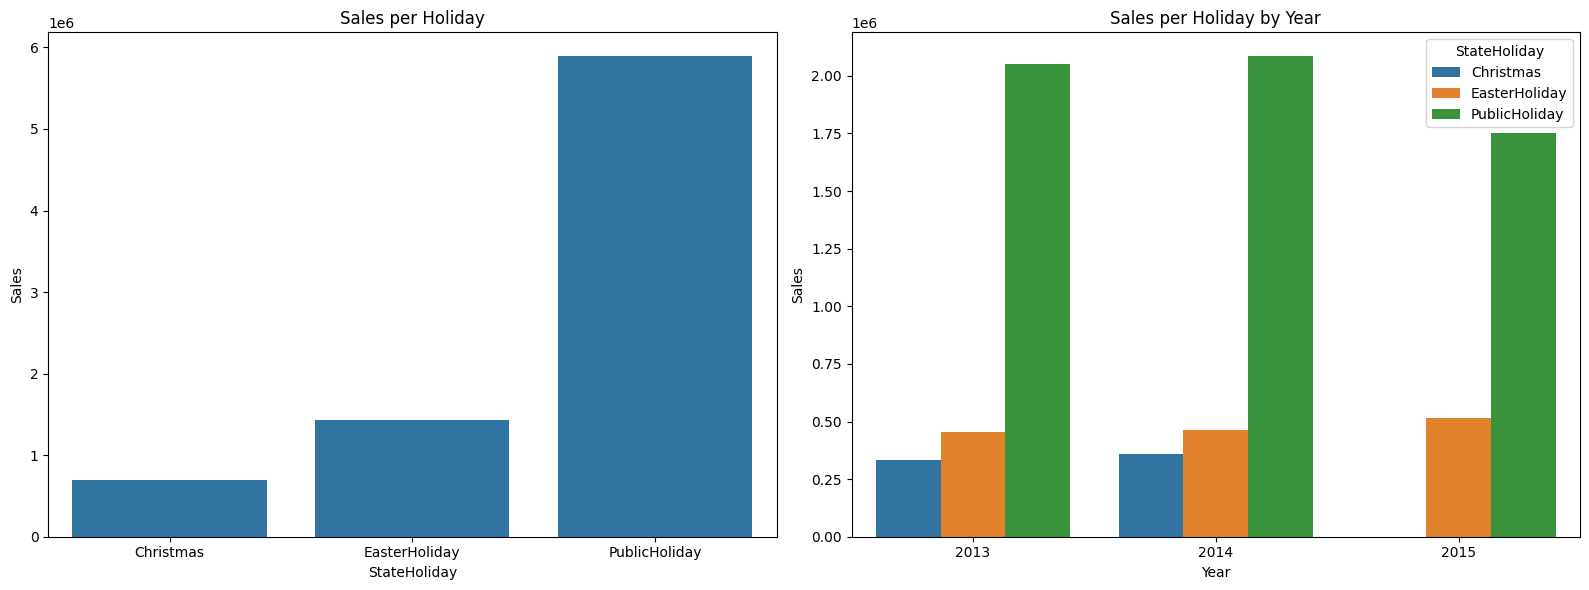

In [26]:
df_train_processed['Date'] = pd.to_datetime(df_train_processed['Date'])
df_train_processed['Year'] = df_train_processed['Date'].dt.year

aux = df_train_processed[df_train_processed['StateHoliday'] != 'RegularDay']
plt.figure(figsize=(16, 6))
# sales per holiday
plt.subplot(1, 2, 1)
aux1 = aux[['StateHoliday', 'Sales']].groupby('StateHoliday').sum().reset_index()
sns.barplot(x = 'StateHoliday', y = 'Sales', data = aux1)
plt.title('Sales per Holiday')

# sales per holiday, year
plt.subplot(1, 2, 2)
aux1 = aux[['Year', 'StateHoliday', 'Sales']].groupby(['Year', 'StateHoliday']).sum().reset_index()
sns.barplot(x = 'Year', y = 'Sales', hue = 'StateHoliday', data = aux1)
plt.title('Sales per Holiday by Year')

plt.tight_layout()
plt.show()

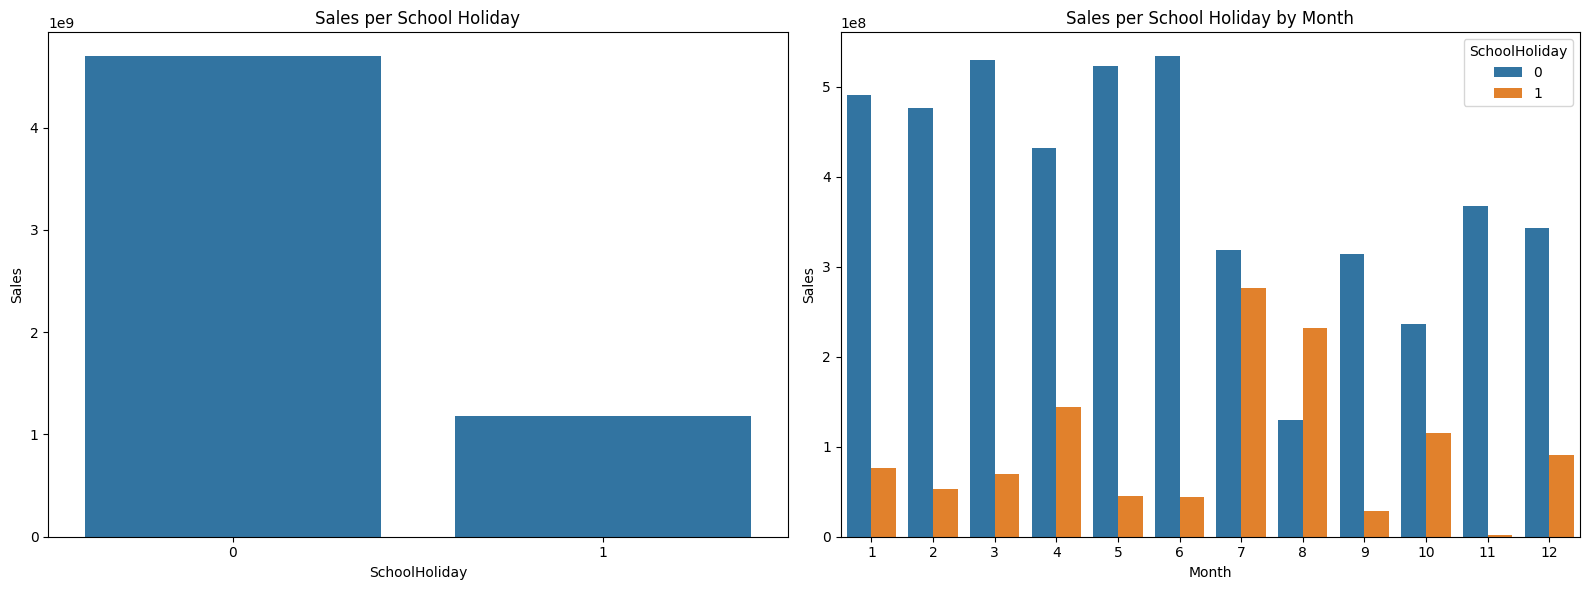

In [27]:
df_train_processed['Month'] = df_train_processed['Date'].dt.month

# bar plot sales per school_holiday
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
aux1 = df_train_processed[['SchoolHoliday','Sales']].groupby('SchoolHoliday').sum().reset_index()
sns.barplot(x = 'SchoolHoliday',y = 'Sales', data = aux1);
plt.title('Sales per School Holiday')

# bar plot sales per school_holiday, month
plt.subplot(1, 2, 2)
aux2 = df_train_processed[['Month','SchoolHoliday','Sales']].groupby(['Month','SchoolHoliday']).sum().reset_index()
sns.barplot(x = 'Month',y = 'Sales',hue = 'SchoolHoliday', data = aux2);
plt.title('Sales per School Holiday by Month')

plt.tight_layout()
plt.show()

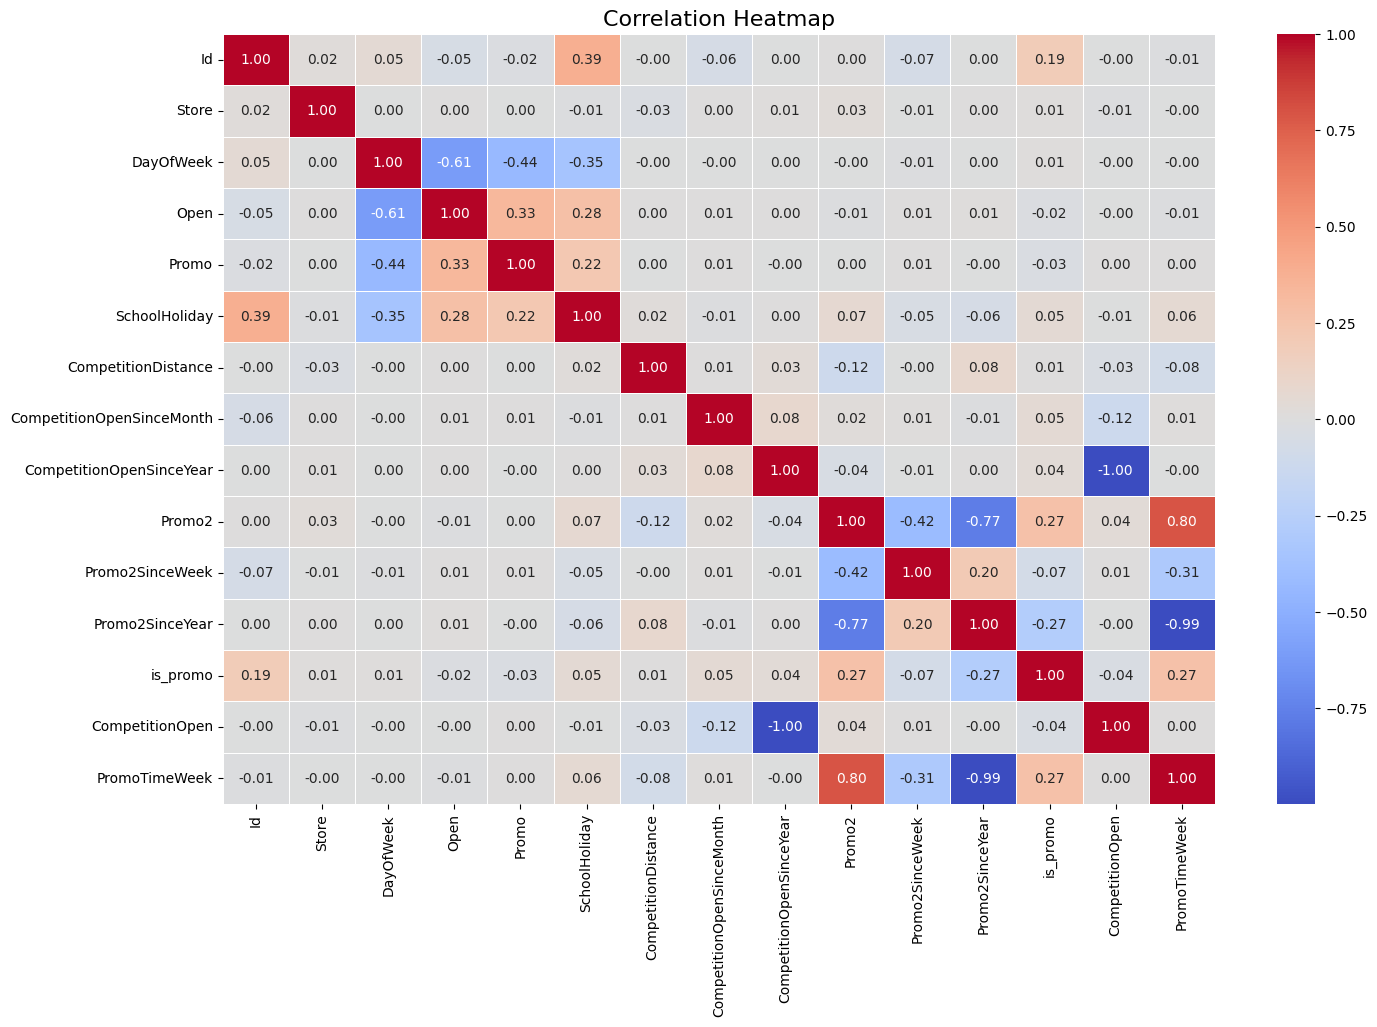

In [28]:
plt.figure(figsize=(16, 10))
correlation = num_attributes.corr(method='pearson')
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap', fontsize=16)
plt.show()

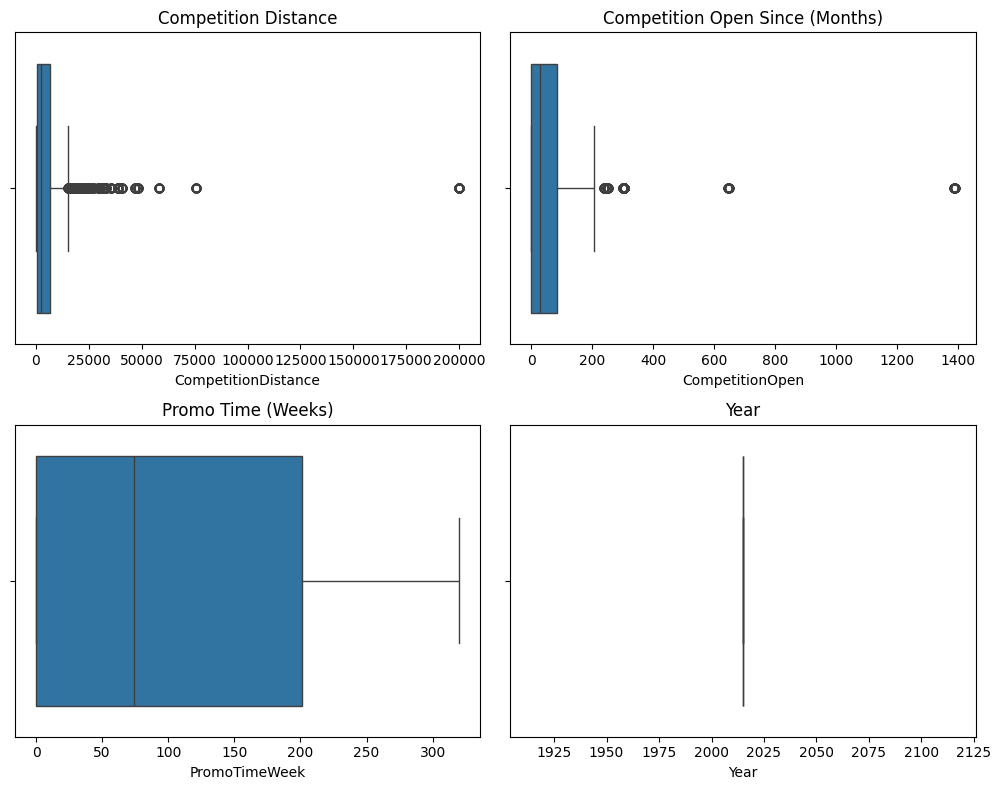

In [29]:
plt.figure(figsize=(10, 8))

plt.subplot(2,2,1)
sns.boxplot(x = 'CompetitionDistance', data = df1)
plt.title('Competition Distance')

plt.subplot(2,2,2)
sns.boxplot(x = 'CompetitionOpen', data = df1)
plt.title('Competition Open Since (Months)')

plt.subplot(2,2,3)
sns.boxplot(x = 'PromoTimeWeek', data = df1)
plt.title('Promo Time (Weeks)')

plt.subplot(2,2,4)
sns.boxplot(x = 'Year', data = df1)
plt.title('Year')

plt.tight_layout()
plt.show()

In [30]:
# columns selected from boruta
cols_selected_boruta = [
        'Store',
        'Promo',
        'StoreType',
        'Assortment',
        'CompetitionDistance',
        'CompetitionOpenSinceMonth',
        'CompetitionOpenSinceYear',
        'Promo2','Promo2SinceWeek',
        'Promo2SinceYear',
        'CompetitionTimeMonth',
        'PromoTimeWeek',
        'DayOfWeekSin',
        'DayOfWeekCos',
        'MonthCos',
        'MonthSin',
        'DaySin',
        'DayCos',
        'WeekOfYearCos',
        'WeekOfYearSin'
]

cols_selected_boruta_full = cols_selected_boruta

In [31]:
import datetime

# Apply necessary feature engineering to df_train_processed
# This ensures that X_train and X_test contain all expected features.

# Handle NaNs for Promo2SinceWeek and Promo2SinceYear in df_train_processed
df_train_processed['Promo2SinceWeek'].fillna(df_train_processed['Date'].dt.isocalendar().week, inplace = True)
df_train_processed['Promo2SinceYear'].fillna(df_train_processed['Date'].dt.year, inplace = True)

# Add Day and ensure WeekOfYear is int
df_train_processed['Day'] = df_train_processed['Date'].dt.day
df_train_processed['WeekOfYear'] = df_train_processed['Date'].dt.isocalendar().week.astype(int)

# Calculate CompetitionTimeMonth (equivalent to CompetitionOpen in df1's feature engineering)
# This uses existing 'Year', 'Month', 'CompetitionOpenSinceYear', 'CompetitionOpenSinceMonth'
df_train_processed['CompetitionTimeMonth'] = 12 * (df_train_processed['Year'] - df_train_processed['CompetitionOpenSinceYear']) + \
                                              (df_train_processed['Month'] - df_train_processed['CompetitionOpenSinceMonth'])

# Calculate PromoSince and PromoTimeWeek for df_train_processed
df_train_processed['PromoSince'] = df_train_processed['Promo2SinceYear'].astype(int).astype(str) + '-' + df_train_processed['Promo2SinceWeek'].astype(int).astype(str)
df_train_processed['PromoSince'] = df_train_processed['PromoSince'].apply(lambda x: datetime.datetime.strptime(x + '-1', '%Y-%W-%w') - datetime.timedelta(days = 7))
df_train_processed['PromoTimeWeek'] = ((df_train_processed['Date'] - df_train_processed['PromoSince'])/7).apply(lambda x: x.days).astype(int)

# Calculate trigonometric features for cyclical date components
# DayOfWeek (1-7)
df_train_processed['DayOfWeekSin'] = np.sin(df_train_processed['DayOfWeek'] * (2 * np.pi / 7))
df_train_processed['DayOfWeekCos'] = np.cos(df_train_processed['DayOfWeek'] * (2 * np.pi / 7))

# Month (1-12)
df_train_processed['MonthSin'] = np.sin(df_train_processed['Month'] * (2 * np.pi / 12))
df_train_processed['MonthCos'] = np.cos(df_train_processed['Month'] * (2 * np.pi / 12))

# Day (1-31)
df_train_processed['DaySin'] = np.sin(df_train_processed['Day'] * (2 * np.pi / 31))
df_train_processed['DayCos'] = np.cos(df_train_processed['Day'] * (2 * np.pi / 31))

# WeekOfYear (1-52/53) - using 52 as a base for periodicity
df_train_processed['WeekOfYearSin'] = np.sin(df_train_processed['WeekOfYear'] * (2 * np.pi / 52))
df_train_processed['WeekOfYearCos'] = np.cos(df_train_processed['WeekOfYear'] * (2 * np.pi / 52))

# training dataset
X_train = df_train_processed[df_train_processed['Date'] < '2015-06-19'].drop('Sales', axis=1)
y_train = df_train_processed[df_train_processed['Date'] < '2015-06-19']['Sales']

# test dataset
X_test = df_train_processed[df_train_processed['Date'] >= '2015-06-19'].drop('Sales', axis=1)
y_test = df_train_processed[df_train_processed['Date'] >= '2015-06-19']['Sales']

print("Training min date: {}".format(X_train['Date'].min()))
print("Training max date: {}".format(X_train['Date'].max()))

print("\nTest Min date: {}".format(X_test['Date'].min()))
print("Test Max Date: {}".format(X_test['Date'].max()))

Training min date: 2013-01-01 00:00:00
Training max date: 2015-06-18 00:00:00

Test Min date: 2015-06-19 00:00:00
Test Max Date: 2015-07-31 00:00:00


# **Machine Learning Modelling**

# **Baseline model**

In [32]:
x_train = X_train[cols_selected_boruta].copy()
x_test = X_test[cols_selected_boruta].copy()

# Convert categorical columns to 'category' dtype for XGBoost
for col in ['StoreType', 'Assortment']:
    x_train[col] = x_train[col].astype('category')
    x_test[col] = x_test[col].astype('category')

x_training = X_train[cols_selected_boruta_full]

In [33]:
def ml_error(model_name, y, yhat):
    rmse = np.sqrt(np.mean((y - yhat)**2))
    return dict(Model = model_name, RMSE = rmse)

aux1 = x_test.copy()
aux1['sales'] = y_test.copy()

#prediction
aux2 = aux1[['Store','sales']].groupby("Store").mean().reset_index().rename(columns = {'sales':'predictions'})
aux1 = pd.merge(aux1,aux2, how = 'left', on = 'Store')

yhat_baseline = aux1['predictions']

#performance
baseline_result = ml_error("Average Model", y_test, yhat_baseline) # y_test and yhat_baseline are already on original scale
baseline_result

{'Model': 'Average Model', 'RMSE': np.float64(3926.097950332285)}

# **XGBoost Regressor**

In [34]:
%%time
# model
model_xgb = xgb.XGBRegressor(objective='reg:squarederror',
                              n_estimators=100,
                              eta=0.01,
                              max_depth=10,
                              subsample=0.7,
                              colsample_bytree=0.9).fit( x_train, y_train )

# prediction
yhat_xgb = model_xgb.predict( x_test )

# performance
xgb_result = ml_error( 'XGBoost Regressor', y_test, yhat_xgb )
xgb_result

CPU times: user 48.3 s, sys: 69 ms, total: 48.3 s
Wall time: 29.1 s


{'Model': 'XGBoost Regressor', 'RMSE': np.float64(2308.9298456256124)}

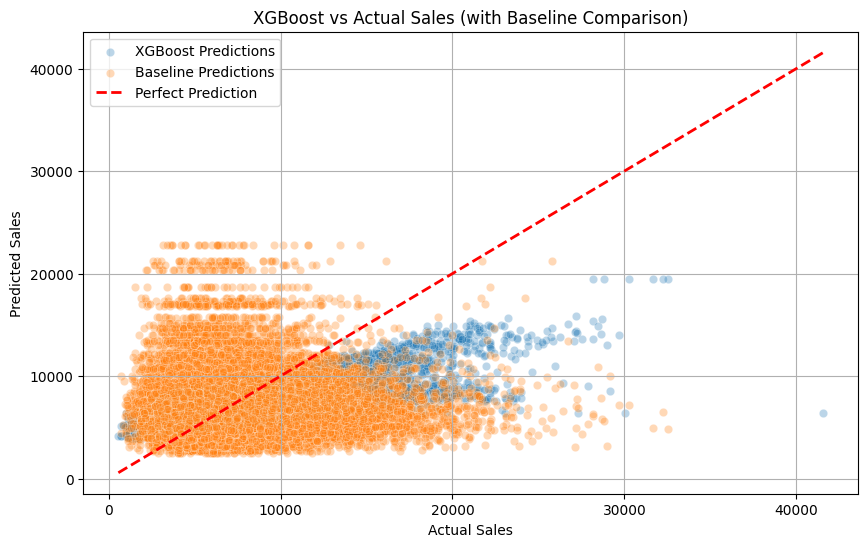

In [35]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x=y_test, y=yhat_xgb, alpha=0.3, label='XGBoost Predictions')
sns.scatterplot(x=y_test, y=yhat_baseline, alpha=0.3, label='Baseline Predictions')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel('Actual Sales')
plt.ylabel('Predicted Sales')
plt.title('XGBoost vs Actual Sales (with Baseline Comparison)')
plt.legend()
plt.grid(True)
plt.show()

In [38]:
# # defining parameters grid
# param = {
#    'n_estimators': [1500, 1700, 2500, 3000, 3500],
#    'eta': [0.01, 0.03],
#    'max_depth': [3, 5, 9],
#    'subsample': [0.1, 0.5, 0.7],
#    'colsample_bytree': [0.3, 0.7, 0.9],
#    'min_child_weight': [3, 8, 15]
#        }

# model_xgb = xgb.XGBRegressor()

# xgb_grid_cv = RandomizedSearchCV(model_xgb, param, verbose = True, cv = 2, n_iter = 5, n_jobs = -1, random_state = 42)
# %timeit -n 1 -r 1 xgb_grid_cv.fit(x_train, y_train)

# print(f'Best estimator: {xgb_grid_cv.best_estimator_}')
# print(f'Best score: {xgb_grid_cv.best_score_}')

import time
from sklearn.model_selection import RandomizedSearchCV
import xgboost as xgb

# Parametrlər şəbəkəsi
param = {
    "n_estimators": [500, 1000, 1500],  # Hələlik bir az azaltsanız daha sürətli işləyər
    "eta": [0.01, 0.03, 0.1],
    "max_depth": [3, 5, 7],
    "subsample": [0.7, 0.9],
    "colsample_bytree": [0.7, 0.9],
    "min_child_weight": [3, 5],
}

model_xgb = xgb.XGBRegressor(
    random_state=42
)  # Reproduksiyalar üçün random_state əlavə etmək yaxşıdır

xgb_grid_cv = RandomizedSearchCV(
    estimator=model_xgb,
    param_distributions=param,
    verbose=1,
    cv=3,  # 2 əvəzinə ən azı 3 məsləhətdir
    n_iter=5,
    n_jobs=-1,
    random_state=42,
)

# Vaxtı %timeit əvəzinə standart Python ilə ölçürük
start_time = time.time()
xgb_grid_cv.fit(x_train, y_train)
end_time = time.time()

print(f"\nİcra olunma vaxtı: {end_time - start_time:.2f} saniyə")
print(f"Best estimator: {xgb_grid_cv.best_estimator_}")
print(f"Best score: {xgb_grid_cv.best_score_}")

Fitting 3 folds for each of 5 candidates, totalling 15 fits

İcra olunma vaxtı: 1228.09 saniyə
Best estimator: XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=0.9, device=None, early_stopping_rounds=None,
             enable_categorical=True, eta=0.1, eval_metric=None,
             feature_types=None, feature_weights=None, gamma=None,
             grow_policy=None, importance_type=None,
             interaction_constraints=None, learning_rate=None, max_bin=None,
             max_cat_threshold=None, max_cat_to_onehot=None,
             max_delta_step=None, max_depth=7, max_leaves=None,
             min_child_weight=5, missing=nan, monotone_constraints=None,
             multi_strategy=None, n_estimators=1000, n_jobs=None, ...)
Best score: 0.851694921652476


In [39]:
# model
model_xgb_tuned = xgb.XGBRegressor(colsample_bytree=0.3,
                                   eta=0.01,
                                   max_depth=9,
                                   min_child_weight=8,
                                   n_estimators=1500,
                                   subsample=0.5)

model_xgb_tuned.fit( x_train, y_train )

# prediction
yhat_xgb_tuned = model_xgb_tuned.predict( x_test )

# performance
xgb_result_tuned = ml_error( 'XGBoost Regressor', np.expm1( y_test ), np.expm1( yhat_xgb_tuned ) )
xgb_result_tuned

{'Model': 'XGBoost Regressor', 'RMSE': np.float64(inf)}